# 02 — Question-Only BiLSTM Baseline | PathVQA

**Capstone:** Question-Type-Aware Multimodal Fusion for Pathology Visual Question Answering (QTAF-Net)

**Goal:** Establish how accurately a model can answer PathVQA questions **without seeing pathology images**. This measures potential question-language bias.

**Experimental rules**
- All trainable weights (embeddings, BiLSTM, classifiers) start **randomly initialized**. No pretrained weights.
- Reuse the **same cleaned data split**, **question vocabulary**, **top-1,000 answer vocabulary**, and **evaluation convention** as the CNN + BiLSTM baseline.
- Two classification heads: yes/no (2 classes) and open-ended (1,000 classes).
- **Oracle answer-type routing** for evaluation, matching the previous baseline: ground-truth yes/no vs open answer type selects which head to score. This is not a deployable end-to-end VQA metric without a predicted router.
- Open-ended answers absent from the training vocabulary receive label `-1`, are excluded from cross-entropy, and count as incorrect in validation.
- Do **not** train on the test split or select models using test accuracy.

**Run cells top-to-bottom.** To restore an existing model later, skip the training cell and use the evaluation section.


## Submission and reproducibility guide (Notebook 02)

**Purpose.** Train and evaluate the **Question-Only BiLSTM** control on PathVQA. This model receives question tokens but **never image pixels**. It uses the same answer-label mapping as Notebook 01 to make comparisons meaningful.

**Kaggle setup.** Enable Internet for the first Hugging Face dataset download (or provide a cached dataset). Attach a Kaggle input dataset containing `late_fusion_latest.pth` from Notebook 01; this file supplies `word2idx` and `open_answer2idx`, **not pretrained model weights**. Enable a GPU if available. The notebook installs `datasets` and imports the other packages it uses (PyTorch, pandas, NumPy, matplotlib, etc.); ensure these are available in the Kaggle runtime.

**Execution order.** Run cells from top to bottom: dependencies → dataset and overlap check → shared mappings → question encoding → loaders → architecture → loss and validation → original training → checkpoint evaluation and plots → fine-tuning → fine-tuned evaluation and backup. Training and fine-tuning can take time. If continuing an existing run, ensure the expected best checkpoint is attached or present before running the restore cells.

**Output interpretation.** Original and fine-tuned scores here are **validation** scores used for model selection. For the dual-head model, the validation function chooses the yes/no or open head from the **ground-truth question type (oracle routing)**. Final held-out test metrics are produced by the separate all-model evaluation notebook. The comparison table with CNN + BiLSTM contains previously recorded reference values, not a fresh evaluation of that model.

**Files and limitations.** Checkpoints, training histories and backup ZIPs are written under `/kaggle/working/`. Recursive checkpoint searches depend on the attached Kaggle input paths. The notebook has not been re-executed during this documentation update; rerunning it requires the original data and checkpoint dependencies.


## 1. Kaggle setup

1. Create a Kaggle notebook named `02_Question_Only_BiLSTM`.
2. Add the original CNN + BiLSTM experiment files as a Kaggle Input, including **`late_fusion_latest.pth`** (the original 1,000-answer checkpoint with vocabulary mappings).
3. Enable GPU if available. The question-only model can also run on CPU.
4. Turn on Internet for the first PathVQA download if the dataset is not cached.

The previous checkpoint is used **only to restore token/answer mappings**, never to initialize model weights.

In [5]:
# Install the Hugging Face datasets package and import reproducibility, data, and PyTorch utilities.
!pip -q install datasets

import os, re, glob, random, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu130
Device: cuda


## 2. Load PathVQA

The expected split sizes are 19,654 train, 6,259 validation, and 6,719 test. We load the test split but **do not use it during training or model selection**.

In [6]:
# Load the published PathVQA splits; keep the test split separate from model selection.
dataset = load_dataset("flaviagiammarino/path-vqa")
print(dataset)
for split in ["train", "validation", "test"]:
    print(f"{split}: {len(dataset[split]):,} samples")
print("Columns:", dataset["train"].column_names)

DatasetDict({
    train: Dataset({
        features: ['image', 'question', 'answer'],
        num_rows: 19654
    })
    validation: Dataset({
        features: ['image', 'question', 'answer'],
        num_rows: 6259
    })
    test: Dataset({
        features: ['image', 'question', 'answer'],
        num_rows: 6719
    })
})
train: 19,654 samples
validation: 6,259 samples
test: 6,719 samples
Columns: ['image', 'question', 'answer']


## 3. Remove train/validation image overlap

The original baseline identified **one shared image** across training and validation and removed **six training question-answer pairs** associated with it.

To reproduce that cleaning, hash decoded RGB image pixels and dimensions. Validation and test remain unchanged. This step reads images only for **data leakage prevention**, not as inputs to the question-only model.

In [4]:
# Hash RGB pixel content to identify image overlap and exclude only overlapping training examples.
def image_hash(image):
    rgb = image.convert("RGB")
    digest = hashlib.sha256()
    digest.update(str(rgb.size).encode())
    digest.update(rgb.tobytes())
    return digest.hexdigest()

validation_image_hashes = {
    image_hash(sample["image"])
    for sample in tqdm(dataset["validation"], desc="Hash validation images")
}
keep_train_indices = [
    i for i, sample in enumerate(tqdm(dataset["train"], desc="Check training images"))
    if image_hash(sample["image"]) not in validation_image_hashes
]
clean_train = dataset["train"].select(keep_train_indices)
clean_val = dataset["validation"]
clean_test = dataset["test"]

print("Original train:", len(dataset["train"]))
print("Clean train:", len(clean_train))
print("Removed:", len(dataset["train"]) - len(clean_train))
print("Validation:", len(clean_val))
assert len(clean_train) == 19648, "Cleaning count differs; inspect dataset version before comparing experiments."

Hash validation images:   0%|          | 0/6259 [00:00<?, ?it/s]

Check training images:   0%|          | 0/19654 [00:00<?, ?it/s]

Original train: 19654
Clean train: 19648
Removed: 6
Validation: 6259


## 4. Restore identical vocabulary mappings

**Critical for a fair comparison:** The original checkpoint stores `word2idx` and `open_answer2idx`. We load only these dictionaries; we **do not** load the previous CNN, BiLSTM, or classifier weights.

If more than one matching checkpoint is found, inspect the printed paths and choose the original 1,000-class checkpoint (not the 2,000-class one).

In [7]:
# Load the shared training-derived vocabulary mappings; do not load CNN + BiLSTM model weights.
checkpoint_candidates = sorted(
    glob.glob("/kaggle/input/**/late_fusion_latest.pth", recursive=True)
    + glob.glob("/kaggle/working/late_fusion_latest.pth")
)
print("Available original checkpoints:")
for i, path in enumerate(checkpoint_candidates):
    print(i, path)

if not checkpoint_candidates:
    raise FileNotFoundError(
        "Add the original 1,000-class late_fusion_latest.pth as a Kaggle Input."
    )
if len(checkpoint_candidates) > 1:
    raise RuntimeError(
        "Multiple original checkpoints found. Set checkpoint_path manually to the correct file."
    )

checkpoint_path = checkpoint_candidates[0]
# The checkpoint was created by your own earlier training code. Do not load untrusted .pth files.
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
word2idx = checkpoint["word2idx"]
open_answer2idx = checkpoint["open_answer2idx"]
del checkpoint

print("Question vocabulary:", len(word2idx))
print("Open answer classes:", len(open_answer2idx))
print("PAD index:", word2idx["<PAD>"], "UNK index:", word2idx["<UNK>"])
assert len(open_answer2idx) == 1000
assert word2idx["<PAD>"] == 0 and word2idx["<UNK>"] == 1

Available original checkpoints:
0 /kaggle/input/datasets/dollarpaisa/cnn-bilstam/late_fusion_latest.pth
Question vocabulary: 3972
Open answer classes: 1000
PAD index: 0 UNK index: 1


## 5. Question and answer encoding

- Lowercase and tokenize questions using the **same regex** as the CNN + BiLSTM experiment.
- Truncate/pad to **32 tokens**.
- Map yes/no to `no=0`, `yes=1`; map open answers to the original top-1,000 vocabulary.
- An unseen open answer gets `-1`.

No image preprocessing is required for the model.

In [8]:
# Apply the shared tokenizer and map answers to the closed or 1,000-class open label space.
MAX_QUESTION_LENGTH = 32

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text).lower().strip())

def encode_question(question):
    ids = [word2idx.get(token, word2idx["<UNK>"]) for token in tokenize(question)]
    ids = ids[:MAX_QUESTION_LENGTH]
    ids += [word2idx["<PAD>"]] * (MAX_QUESTION_LENGTH - len(ids))
    return ids

def encode_answer(answer):
    answer = str(answer).lower().strip()
    if answer == "no":
        return 0, 0
    if answer == "yes":
        return 0, 1
    return 1, open_answer2idx.get(answer, -1)

print("Example:", clean_train[0]["question"])
print("Encoded:", encode_question(clean_train[0]["question"]))
print("Answer:", clean_train[0]["answer"], encode_answer(clean_train[0]["answer"]))

Example: where are liver stem cells (oval cells) located?
Encoded: [2, 3, 4, 5, 6, 7, 8, 6, 9, 10, 11, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Answer: in the canals of hering (1, 779)


## 6. Check open-answer coverage

Coverage is the proportion of validation open answers represented among the 1,000 training answer classes. The previous experiment found approximately **66.56%**. Open-ended accuracy cannot exceed this coverage under exact-match top-1,000 classification.

In [9]:
# Measure the proportion of validation open answers representable by the fixed answer vocabulary.
open_total = 0
open_covered = 0
for answer in clean_val["answer"]:
    answer_type, label = encode_answer(answer)
    if answer_type == 1:
        open_total += 1
        open_covered += int(label >= 0)
print(f"Open validation examples: {open_total}")
print(f"Covered open answers: {open_covered}")
print(f"Coverage: {open_covered/open_total:.2%}")

Open validation examples: 3134
Covered open answers: 2086
Coverage: 66.56%


## 7. Question-only Dataset and DataLoaders

Each item contains **only** `question`, `answer_type`, and `answer_label`. There is no `image` field.

Batch size **32**, with `num_workers=2` as in your prior notebook.

In [10]:
# Create question-only batches: no image tensor is supplied to this baseline.
class QuestionOnlyPathVQADataset(Dataset):
    def __init__(self, hf_split):
        self.questions = hf_split["question"]
        self.answers = hf_split["answer"]

    def __len__(self):
        return len(self.questions)

    def __getitem__(self, idx):
        answer_type, answer_label = encode_answer(self.answers[idx])
        return {
            "question": torch.tensor(encode_question(self.questions[idx]), dtype=torch.long),
            "answer_type": torch.tensor(answer_type, dtype=torch.long),
            "answer_label": torch.tensor(answer_label, dtype=torch.long),
        }

train_dataset = QuestionOnlyPathVQADataset(clean_train)
val_dataset = QuestionOnlyPathVQADataset(clean_val)

BATCH_SIZE = 32
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

batch = next(iter(train_loader))
print("Train / validation:", len(train_dataset), len(val_dataset))
print("Train / validation batches:", len(train_loader), len(val_loader))
for key, value in batch.items():
    print(key, value.shape)
assert "image" not in batch

Train / validation: 19648 6259
Train / validation batches: 614 196
question torch.Size([32, 32])
answer_type torch.Size([32])
answer_label torch.Size([32])


## 8. Question-Only BiLSTM architecture (from scratch)

**Question → trainable embedding (128) → bidirectional LSTM (128 per direction) → 256-d question representation → shared fully connected layer (256) → two classification heads.**

The BiLSTM encoder matches the language encoder used in your late-fusion baseline. The shared projection and output heads match its dimensions, but this model **does not receive image features**.

**All model parameters are randomly initialized.**

In [11]:
# Encode token sequences with trainable embeddings and a bidirectional LSTM, then predict via two answer heads.
class QuestionEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            input_size=embedding_dim, hidden_size=hidden_dim,
            batch_first=True, bidirectional=True
        )

    def forward(self, questions):
        embedded = self.embedding(questions)
        lengths = (questions != 0).sum(dim=1).clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        return torch.cat([hidden[-2], hidden[-1]], dim=1)


class QuestionOnlyBiLSTM(nn.Module):
    def __init__(self, vocab_size, num_open_answers=1000):
        super().__init__()
        self.question_encoder = QuestionEncoder(vocab_size)
        self.fusion = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.yes_no_head = nn.Linear(256, 2)
        self.open_head = nn.Linear(256, num_open_answers)

    def forward(self, questions):
        features = self.question_encoder(questions)
        shared = self.fusion(features)
        return self.yes_no_head(shared), self.open_head(shared)


model = QuestionOnlyBiLSTM(
    vocab_size=len(word2idx), num_open_answers=len(open_answer2idx)
).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

QuestionOnlyBiLSTM(
  (question_encoder): QuestionEncoder(
    (embedding): Embedding(3972, 128, padding_idx=0)
    (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  )
  (fusion): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (yes_no_head): Linear(in_features=256, out_features=2, bias=True)
  (open_head): Linear(in_features=256, out_features=1000, bias=True)
)
Trainable parameters: 1095914


## 9. Training objective

Use the same **two-head cross-entropy loss** as the late-fusion baseline:

- Yes/no examples contribute to the yes/no head.
- Open examples contribute to the 1,000-class open head only if the answer is in vocabulary.
- If a batch has both types, average the two losses equally.

This preserves the previous training convention.

In [12]:
# Apply cross-entropy only to the appropriate answer head for each labeled question type.
def compute_loss(yes_no_logits, open_logits, answer_types, answer_labels):
    closed_mask = answer_types == 0
    open_mask = (answer_types == 1) & (answer_labels >= 0)
    losses = []
    if closed_mask.any():
        losses.append(F.cross_entropy(
            yes_no_logits[closed_mask], answer_labels[closed_mask]
        ))
    if open_mask.any():
        losses.append(F.cross_entropy(
            open_logits[open_mask], answer_labels[open_mask]
        ))
    if not losses:
        return (yes_no_logits.sum() + open_logits.sum()) * 0
    return sum(losses) / len(losses)

model.train()
yes_no_logits, open_logits = model(batch["question"].to(device))
loss = compute_loss(
    yes_no_logits, open_logits,
    batch["answer_type"].to(device), batch["answer_label"].to(device)
)
print("Yes/no logits:", tuple(yes_no_logits.shape))
print("Open logits:", tuple(open_logits.shape))
print("Initial batch loss:", round(loss.item(), 4))

Yes/no logits: (32, 2)
Open logits: (32, 1000)
Initial batch loss: 3.7859


## 10. Training and validation functions

Training uses gradient clipping at 1.0. Validation reports **fractions** internally and percentages when printed.

**Important:** Validation selects the correct head using the ground-truth answer type (oracle routing), exactly as in your previous baseline. Out-of-vocabulary open answers are counted as incorrect.

In [13]:
# Train with gradient clipping; validate using ground-truth answer types (oracle routing).
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss, total_samples = 0.0, 0
    for batch in tqdm(loader, desc="Training"):
        questions = batch["question"].to(device)
        answer_types = batch["answer_type"].to(device)
        answer_labels = batch["answer_label"].to(device)

        optimizer.zero_grad()
        yes_no_logits, open_logits = model(questions)
        loss = compute_loss(yes_no_logits, open_logits, answer_types, answer_labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        size = questions.size(0)
        total_loss += loss.item() * size
        total_samples += size
    return total_loss / total_samples

@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    closed_total = closed_correct = 0
    open_total = open_correct = 0
    for batch in tqdm(loader, desc="Validation"):
        questions = batch["question"].to(device)
        answer_types = batch["answer_type"].to(device)
        answer_labels = batch["answer_label"].to(device)
        yes_no_logits, open_logits = model(questions)
        closed_mask = answer_types == 0
        open_mask = answer_types == 1
        closed_correct += ((yes_no_logits.argmax(1) == answer_labels) & closed_mask).sum().item()
        open_correct += ((open_logits.argmax(1) == answer_labels) & open_mask).sum().item()
        closed_total += closed_mask.sum().item()
        open_total += open_mask.sum().item()

    total = closed_total + open_total
    return {
        "overall_accuracy": (closed_correct + open_correct) / max(total, 1),
        "closed_accuracy": closed_correct / max(closed_total, 1),
        "open_accuracy": open_correct / max(open_total, 1),
    }
print("Training and validation functions ready.")

Training and validation functions ready.


## 11. Train Question-Only BiLSTM (up to 30 epochs)

**Training settings:** Adam, learning rate `0.001`, weight decay `1e-5`, batch size 32, patience 5. Save:
- `best_question_only_bilstm.pth`: best validation-accuracy model
- `question_only_bilstm_latest.pth`: model/optimizer state, vocabulary and history
- `question_only_bilstm_history.csv`: metrics by epoch

**Skip this cell if restoring an already trained question-only checkpoint.**

In [14]:
# Train with early stopping and save the best validation checkpoint plus history for reproducibility.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
MAX_EPOCHS = 30
PATIENCE = 5
best_accuracy = -1.0
best_epoch = 0
epochs_without_improvement = 0
history = []

best_path = "/kaggle/working/best_question_only_bilstm.pth"
latest_path = "/kaggle/working/question_only_bilstm_latest.pth"
history_path = "/kaggle/working/question_only_bilstm_history.csv"

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, device)
    metrics = validate(model, val_loader, device)
    overall = metrics["overall_accuracy"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "overall_accuracy": overall,
        "yes_no_accuracy": metrics["closed_accuracy"],
        "open_accuracy": metrics["open_accuracy"],
    })
    print(
        f"Epoch {epoch:02d} | Loss: {train_loss:.4f} | "
        f"Overall: {overall:.2%} | "
        f"Yes/No: {metrics['closed_accuracy']:.2%} | "
        f"Open: {metrics['open_accuracy']:.2%}"
    )

    if overall > best_accuracy:
        best_accuracy = overall
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(model.state_dict(), best_path)
        print("New best model saved!")
    else:
        epochs_without_improvement += 1

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_accuracy": best_accuracy,
        "best_epoch": best_epoch,
        "word2idx": word2idx,
        "open_answer2idx": open_answer2idx,
        "model_name": "QuestionOnlyBiLSTM",
    }, latest_path)
    pd.DataFrame(history).to_csv(history_path, index=False)

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("Best epoch:", best_epoch)
print(f"Best overall validation accuracy: {best_accuracy:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

AssertionError:   File "/usr/lib/python3.13/multiprocessing/pro

Epoch 01 | Loss: 2.5718 | Overall: 45.41% | Yes/No: 81.47% | Open: 9.44%
New best model saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionErrorException ignored in: : can only test a child process<function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (62 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>can only test a child process

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 15 | Loss: 1.7225 | Overall: 48.09% | Yes/No: 85.09% | Open: 11.20%
Early stopping triggered.
Best epoch: 10
Best overall validation accuracy: 48.12%


## 12. Restore and evaluate the best question-only model

This cell works after fresh training or after uploading `best_question_only_bilstm.pth` to Kaggle Inputs. The vocabulary must match the one used during training.

In [15]:
# Reload the best original checkpoint rather than assuming the final epoch performed best.
best_candidates = (
    glob.glob("/kaggle/working/best_question_only_bilstm.pth")
    + glob.glob("/kaggle/input/**/best_question_only_bilstm.pth", recursive=True)
)
if not best_candidates:
    raise FileNotFoundError("Train the model or upload best_question_only_bilstm.pth.")
if len(best_candidates) > 1:
    print("Using checkpoint:", best_candidates[0])
model.load_state_dict(
    torch.load(best_candidates[0], map_location=device, weights_only=True)
)
best_metrics = validate(model, val_loader, device)
print("\nBEST QUESTION-ONLY BiLSTM RESULTS")
print(f"Overall accuracy: {best_metrics['overall_accuracy']:.2%}")
print(f"Yes/No accuracy: {best_metrics['closed_accuracy']:.2%}")
print(f"Open-ended accuracy: {best_metrics['open_accuracy']:.2%}")

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    
if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te


BEST QUESTION-ONLY BiLSTM RESULTS
Overall accuracy: 48.12%
Yes/No accuracy: 85.02%
Open-ended accuracy: 11.33%


## 13. Plot training curves

Use the recorded history from the current run or an uploaded CSV. **This plot does not retrain the model.**

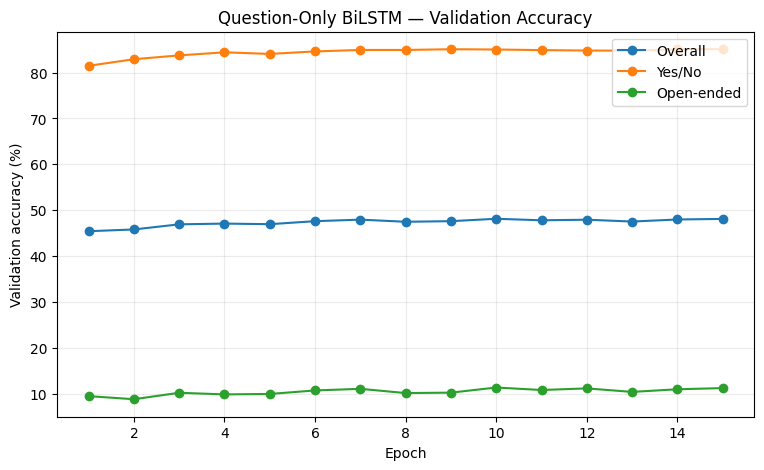

In [16]:
# Plot the recorded training/validation history; the figure does not retrain the model.
import matplotlib.pyplot as plt

history_candidates = (
    glob.glob("/kaggle/working/question_only_bilstm_history.csv")
    + glob.glob("/kaggle/input/**/question_only_bilstm_history.csv", recursive=True)
)
if not history_candidates:
    print("No training-history CSV found yet.")
else:
    df = pd.read_csv(history_candidates[0])
    plt.figure(figsize=(9, 5))
    for col, label in [
        ("overall_accuracy", "Overall"),
        ("yes_no_accuracy", "Yes/No"),
        ("open_accuracy", "Open-ended")
    ]:
        plt.plot(df["epoch"], df[col] * 100, marker="o", label=label)
    plt.xlabel("Epoch")
    plt.ylabel("Validation accuracy (%)")
    plt.title("Question-Only BiLSTM — Validation Accuracy")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

## 14. Compare against the CNN + BiLSTM baseline

These are your **previously reported** CNN + BiLSTM validation results. The question-only row is computed from the checkpoint evaluated above.

**Interpretation:** If question-only performance approaches multimodal performance, it suggests substantial information is available from question phrasing and dataset answer priors. It does **not** prove that the multimodal model ignores images; additional controlled experiments are needed.

In [17]:
# Compare recorded validation scores with the multimodal baseline; these are not test results.
comparison = pd.DataFrame([
    {"Model": "CNN + BiLSTM (original 1K)", "Overall (%)": 53.40, "Yes/No (%)": 85.86, "Open (%)": 21.03},
    {"Model": "CNN + BiLSTM (fine-tuned 1K)", "Overall (%)": 54.42, "Yes/No (%)": 86.43, "Open (%)": 22.50},
    {"Model": "CNN + BiLSTM (2K)", "Overall (%)": 52.63, "Yes/No (%)": 85.89, "Open (%)": 19.46},
    {"Model": "Question-Only BiLSTM (1K)", "Overall (%)": 100*best_metrics["overall_accuracy"],
     "Yes/No (%)": 100*best_metrics["closed_accuracy"], "Open (%)": 100*best_metrics["open_accuracy"]},
])
display(comparison.round(2))
comparison.to_csv("/kaggle/working/question_only_comparison.csv", index=False)

,Model,Overall (%),Yes/No (%),Open (%)
0,CNN + BiLSTM (original 1K),53.40,85.86,21.03
1,CNN + BiLSTM (fine-tuned 1K),54.42,86.43,22.50
2,CNN + BiLSTM (2K),52.63,85.89,19.46
3,Question-Only BiLSTM (1K),48.12,85.02,11.33


## 15. Backup files for the capstone

The ZIP includes the model's checkpoint, latest training state, training history and comparison CSV, if available. The original CNN + BiLSTM files remain untouched.

**Before closing Kaggle:** download the ZIP or save a Kaggle notebook version with outputs.

In [18]:
# Bundle existing outputs and checkpoints for download from Kaggle.
import zipfile

filenames = [
    "best_question_only_bilstm.pth",
    "question_only_bilstm_latest.pth",
    "question_only_bilstm_history.csv",
    "question_only_comparison.csv",
]
zip_path = "/kaggle/working/question_only_bilstm_backup.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in filenames:
        path = "/kaggle/working/" + filename
        if os.path.exists(path):
            archive.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not yet available:", filename)
print("Backup:", zip_path)

Added: best_question_only_bilstm.pth
Added: question_only_bilstm_latest.pth
Added: question_only_bilstm_history.csv
Added: question_only_comparison.csv
Backup: /kaggle/working/question_only_bilstm_backup.zip


# Fine-tuning A — Question-Only BiLSTM (learning rate 0.0001)

Goal: Continue training from the best original Question-Only BiLSTM checkpoint, using the same fine-tuning recipe as the CNN + BiLSTM experiment. This is continued training of your own model, not use of pretrained external weights.

Settings: Adam, lr=0.0001, weight_decay=1e-5, maximum 10 additional epochs, early-stopping patience 3, batch size 32. The original best checkpoint is never overwritten.

Important: Run sections 1–10 to define the dataset, vocabulary, model and functions, then run this section. If the original best checkpoint is in Kaggle Inputs, the next cell will find it. Do not rerun the original 30-epoch training cell (Section 11).

In [19]:
# Restore the best original question-only checkpoint as the starting point for fine-tuning.
import glob
import torch
import pandas as pd

original_best_candidates = (
    glob.glob('/kaggle/working/best_question_only_bilstm.pth')
    + glob.glob('/kaggle/input/**/best_question_only_bilstm.pth', recursive=True)
)
if not original_best_candidates:
    raise FileNotFoundError('Upload best_question_only_bilstm.pth as a Kaggle Input or train the original model first.')
if len(original_best_candidates) > 1:
    print('Multiple checkpoint candidates found; using:', original_best_candidates[0])
original_best_path = original_best_candidates[0]

# Reset to the best ORIGINAL model, so fine-tuning is reproducible and
# never accidentally starts from the final early-stopped epoch.
model.load_state_dict(torch.load(original_best_path, map_location=device, weights_only=True))
original_metrics = validate(model, val_loader, device)
print('Loaded original best checkpoint:', original_best_path)
print(f"Original overall: {original_metrics['overall_accuracy']:.2%}")
print(f"Original yes/no: {original_metrics['closed_accuracy']:.2%}")
print(f"Original open: {original_metrics['open_accuracy']:.2%}")

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Loaded original best checkpoint: /kaggle/working/best_question_only_bilstm.pth
Original overall: 48.12%
Original yes/no: 85.02%
Original open: 11.33%


# 16.1 Train the fine-tuned model

This experiment starts from the original best weights with a new Adam optimizer. The best validation model is saved whenever its overall accuracy exceeds the original checkpoint's accuracy. If it does not improve, the original model remains your best baseline.

In [20]:
# Fine-tune with a lower learning rate and independent early stopping/checkpoint selection.
finetune_optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)
MAX_FINETUNE_EPOCHS = 10
FINETUNE_PATIENCE = 3
finetune_best_accuracy = original_metrics['overall_accuracy']  # FRACTION, not percent
finetune_best_epoch = 0
finetune_no_improvement = 0
finetune_history = []

finetune_best_path = '/kaggle/working/best_question_only_bilstm_finetuned.pth'
finetune_latest_path = '/kaggle/working/question_only_bilstm_finetune_latest.pth'
finetune_history_path = '/kaggle/working/question_only_bilstm_finetune_history.csv'

# Save the original weights as the starting best; the fine-tuned checkpoint
# always exists even if no fine-tuning epoch improves validation accuracy.
torch.save(model.state_dict(), finetune_best_path)

for ft_epoch in range(1, MAX_FINETUNE_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, finetune_optimizer, device)
    metrics = validate(model, val_loader, device)
    overall = metrics['overall_accuracy']
    finetune_history.append({
        'finetune_epoch': ft_epoch,
        'train_loss': train_loss,
        'overall_accuracy': overall,
        'yes_no_accuracy': metrics['closed_accuracy'],
        'open_accuracy': metrics['open_accuracy'],
    })
    print(
        f"Fine-tune epoch {ft_epoch:02d} | Loss: {train_loss:.4f} | "
        f"Overall: {overall:.2%} | Yes/No: {metrics['closed_accuracy']:.2%} | "
        f"Open: {metrics['open_accuracy']:.2%}"
    )
    if overall > finetune_best_accuracy:
        finetune_best_accuracy = overall
        finetune_best_epoch = ft_epoch
        finetune_no_improvement = 0
        torch.save(model.state_dict(), finetune_best_path)
        print('New best fine-tuned model saved!')
    else:
        finetune_no_improvement += 1

    torch.save({
        'epoch': ft_epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': finetune_optimizer.state_dict(),
        'history': finetune_history,
        'best_accuracy': finetune_best_accuracy,
        'best_epoch': finetune_best_epoch,
        'word2idx': word2idx,
        'open_answer2idx': open_answer2idx,
    }, finetune_latest_path)
    pd.DataFrame(finetune_history).to_csv(finetune_history_path, index=False)
    if finetune_no_improvement >= FINETUNE_PATIENCE:
        print('Fine-tuning early stopping triggered.')
        break

print('Best additional fine-tuning epoch:', finetune_best_epoch)
print(f'Best validation accuracy: {finetune_best_accuracy:.2%}')
if finetune_best_epoch == 0:
    print('No fine-tuning epoch beat the original checkpoint.')

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Exception ignored in:     assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>

Traceback (most recent call last):
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
:     self._shutdown_workers()can only test a child process
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    if w.is_alive():
  File "/usr/lib/

Fine-tune epoch 01 | Loss: 1.7175 | Overall: 48.04% | Yes/No: 85.09% | Open: 11.10%


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (20 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    Traceback (most recent call last):
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    if w.is_alive():AssertionError
: can only test a child process  File "/usr/lib/p

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    if w.is_alive():    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    AssertionErrorif w.is_alive():: 
  File "/usr/lib/python3.13/multiprocessing/pro

Fine-tune epoch 06 | Loss: 1.6952 | Overall: 48.07% | Yes/No: 84.93% | Open: 11.33%
Fine-tuning early stopping triggered.
Best additional fine-tuning epoch: 3
Best validation accuracy: 48.20%


# 16.2 Evaluate the best fine-tuned checkpoint
Always evaluate best saved weights, not the last epoch's weights. This section also works after uploading best_question_only_bilstm_finetuned.pth as a Kaggle Input.

In [21]:
# Evaluate the best fine-tuned weights on validation using the existing evaluation function.
fine_candidates = (
    glob.glob('/kaggle/working/best_question_only_bilstm_finetuned.pth')
    + glob.glob('/kaggle/input/**/best_question_only_bilstm_finetuned.pth', recursive=True)
)
if not fine_candidates:
    raise FileNotFoundError('Run fine-tuning or upload best_question_only_bilstm_finetuned.pth.')
model.load_state_dict(torch.load(fine_candidates[0], map_location=device, weights_only=True))
fine_metrics = validate(model, val_loader, device)
print('BEST QUESTION-ONLY BiLSTM AFTER FINE-TUNING')
print(f"Overall accuracy: {fine_metrics['overall_accuracy']:.2%}")
print(f"Yes/No accuracy: {fine_metrics['closed_accuracy']:.2%}")
print(f"Open-ended accuracy: {fine_metrics['open_accuracy']:.2%}")
print('Checkpoint:', fine_candidates[0])

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()Exception ignored in: 
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a79eabe27a0>
    if w.is_alive():Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()

AssertionError:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
can only test a child process    
if w.is_alive():
  File "/usr/lib/

BEST QUESTION-ONLY BiLSTM AFTER FINE-TUNING
Overall accuracy: 48.20%
Yes/No accuracy: 85.25%
Open-ended accuracy: 11.26%
Checkpoint: /kaggle/working/best_question_only_bilstm_finetuned.pth


# 16.3 Compare original and fine-tuned results
The first row uses the original validation results you reported (48.12% / 85.02% / 11.33%). The second row is calculated from the checkpoint evaluated above. Keep both results for your capstone report.

In [22]:
# Summarize original versus fine-tuned validation metrics, not final held-out test metrics.
finetune_comparison = pd.DataFrame([
    {'Model': 'Question-Only BiLSTM (original)', 'Overall (%)': 48.12, 'Yes/No (%)': 85.02, 'Open (%)': 11.33},
    {'Model': 'Question-Only BiLSTM (fine-tuned)',
     'Overall (%)': 100*fine_metrics['overall_accuracy'],
     'Yes/No (%)': 100*fine_metrics['closed_accuracy'],
     'Open (%)': 100*fine_metrics['open_accuracy']},
])
display(finetune_comparison.round(2))
finetune_comparison.to_csv('/kaggle/working/question_only_finetune_comparison.csv', index=False)

,Model,Overall (%),Yes/No (%),Open (%)
0,Question-Only BiLSTM (original),48.12,85.02,11.33
1,Question-Only BiLSTM (fine-tuned),48.20,85.25,11.26


# 16.4 Back up original and fine-tuned experiments
Download the ZIP from Kaggle Output before ending your session. The ZIP includes both models' files if present.

In [23]:
# Archive original and fine-tuned artifacts for the project submission.
import zipfile, os
backup_names = [
    'best_question_only_bilstm.pth',
    'question_only_bilstm_latest.pth',
    'question_only_bilstm_history.csv',
    'best_question_only_bilstm_finetuned.pth',
    'question_only_bilstm_finetune_latest.pth',
    'question_only_bilstm_finetune_history.csv',
    'question_only_finetune_comparison.csv',
]
backup_path = '/kaggle/working/question_only_with_finetuning_backup.zip'
with zipfile.ZipFile(backup_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for name in backup_names:
        file_path = '/kaggle/working/' + name
        if os.path.isfile(file_path):
            z.write(file_path, arcname=name)
            print('Added:', name)
        else:
            print('Not in working directory:', name)
print('Backup ready:', backup_path)

Added: best_question_only_bilstm.pth
Added: question_only_bilstm_latest.pth
Added: question_only_bilstm_history.csv
Added: best_question_only_bilstm_finetuned.pth
Added: question_only_bilstm_finetune_latest.pth
Added: question_only_bilstm_finetune_history.csv
Added: question_only_finetune_comparison.csv
Backup ready: /kaggle/working/question_only_with_finetuning_backup.zip
